# Cvičenie IV – Kalmanove filtre a priestorové dáta

-------------
## Kalmanov filter

Cieľom je pomocou Kalmanovho filtra odhadnúť skrytý stav $x_t$ z pozorovaných hodnôt $y_t$.

Pracuje v dvoch krokoch:

1. Predikcia – na základe predchádzajúceho odhadu predpovedá aktuálny stav.
2. Aktualizácia – po získaní nového pozorovania opraví predikciu pomocou Kalmanovho zisku.

Kalmanov zisk určuje, akú váhu priradíme novej pozorovanej hodnote v porovnaní s predchádzajúcou predikciou.

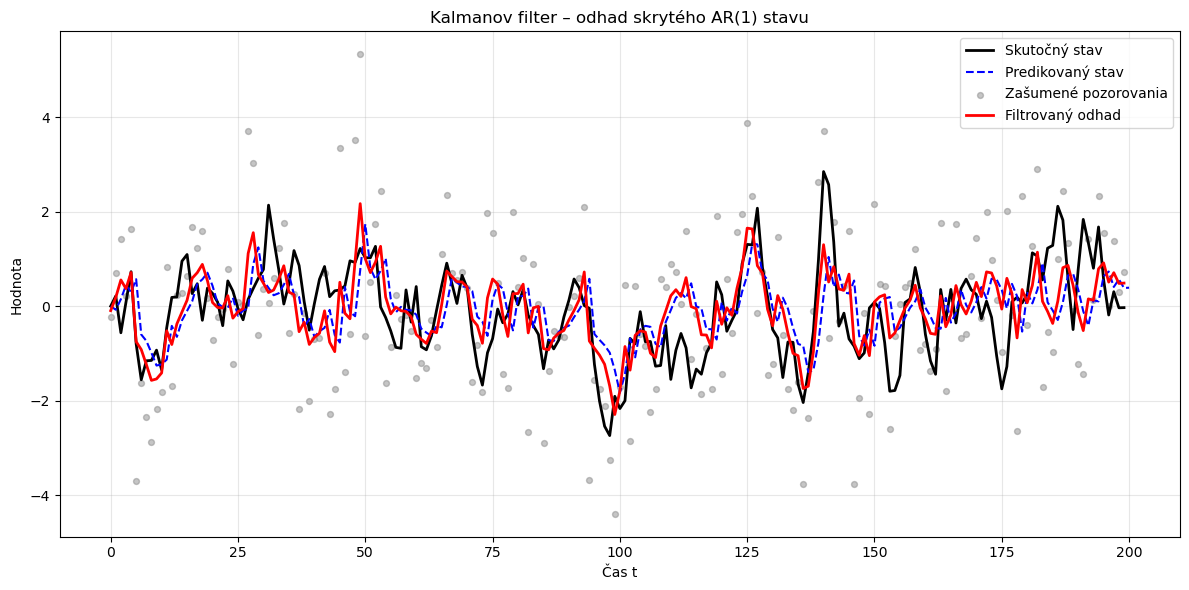

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.kalman_filter import KalmanFilter

# 1. Parametre stavového modelu
rng = np.random.default_rng(42)

# 1. Parametre stavového modelu
n = 200
phi = 0.8
Q = 0.5
R = 2.0

# 2. Simulácia skrytého AR(1) stavu
state = np.zeros(n)

for t in range(1, n):
    w_t = rng.normal(0, np.sqrt(Q))
    state[t] = phi * state[t - 1] + w_t

# 3. Vytvorenie zašumených pozorovaní
v = rng.normal(0, np.sqrt(R), size=n)
observations = state + v

# TODO:
# 1. Vytvorte objekt KalmanFilter pre jednu pozorovanú
#    premennú a jeden skrytý stav.
#
# 2. Odovzdajte filtru zašumené pozorovania observations
#    pomocou metódy bind().
#
# 3. Nastavte matice stavového modelu:
#    - transition: autoregresný koeficient phi,
#    - design: vzťah medzi stavom a pozorovaním = 1,
#    - selection: spôsob vstupu stavového šumu = 1,
#    - state_cov: rozptyl Q,
#    - obs_cov: rozptyl R.
#
# 4. Inicializujte filter s .initialize_known() a .filter()
#   - Počiatočný odhad stavu je 0.
#   - Počiatočná neistota vychádza zo stacionárneho AR(1): [[Q / (1 - phi**2)]].
#
# 5. Získajte predikovaný skrytý stav a filtrovaný skrytý stav.
#
# 6. Vykreslite skutočný stav, Kalmanovu predikciu, zašumené pozorovania
#     a filtrovaný odhad v jednom grafe.

# 4. Vytvorenie Kalmanovho filtra
kf = KalmanFilter(
    k_endog=1,
    k_states=1,
    k_posdef=1
)

# 5. Pripojenie pozorovaní
kf.bind(observations)

# 6. Nastavenie matíc stavového modelu
kf.transition = np.array([[phi]])
kf.design = np.array([[1.0]])
kf.selection = np.array([[1.0]])
kf.state_cov = np.array([[Q]])
kf.obs_cov = np.array([[R]])

# 7. Inicializácia filtra
initial_state = np.array([0.0])
initial_cov = np.array([[Q / (1 - phi**2)]])

kf.initialize_known(initial_state, initial_cov)

# 8. Spustenie Kalmanovho filtra
results = kf.filter()

# 9. Predikovaný a filtrovaný skrytý stav
predicted_state = results.predicted_state[0, :]
filtered_state = results.filtered_state[0, :]

# 10. Vykreslenie výsledkov
plt.figure(figsize=(12, 6))

plt.plot(state, label="Skutočný stav", color="black", linewidth=2)
plt.plot(
    predicted_state,
    label="Predikovaný stav",
    color="blue",
    linestyle="--"
)
plt.scatter(
    np.arange(n),
    observations,
    label="Zašumené pozorovania",
    color="gray",
    alpha=0.45,
    s=18
)
plt.plot(
    filtered_state,
    label="Filtrovaný odhad",
    color="red",
    linewidth=2
)

plt.title("Kalmanov filter – odhad skrytého AR(1) stavu")
plt.xlabel("Čas t")
plt.ylabel("Hodnota")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

--------
## Priestorové dáta

Kde sa javy dejú?

* Analýza hustoty zaľudnenia, šírenie infekcií, monitorovanie mobility či pohybu zveri.

Dva základné typy:

1. Vektory (Vector data): Body, čiary alebo polygóny
    
2. Rastre (Raster data)



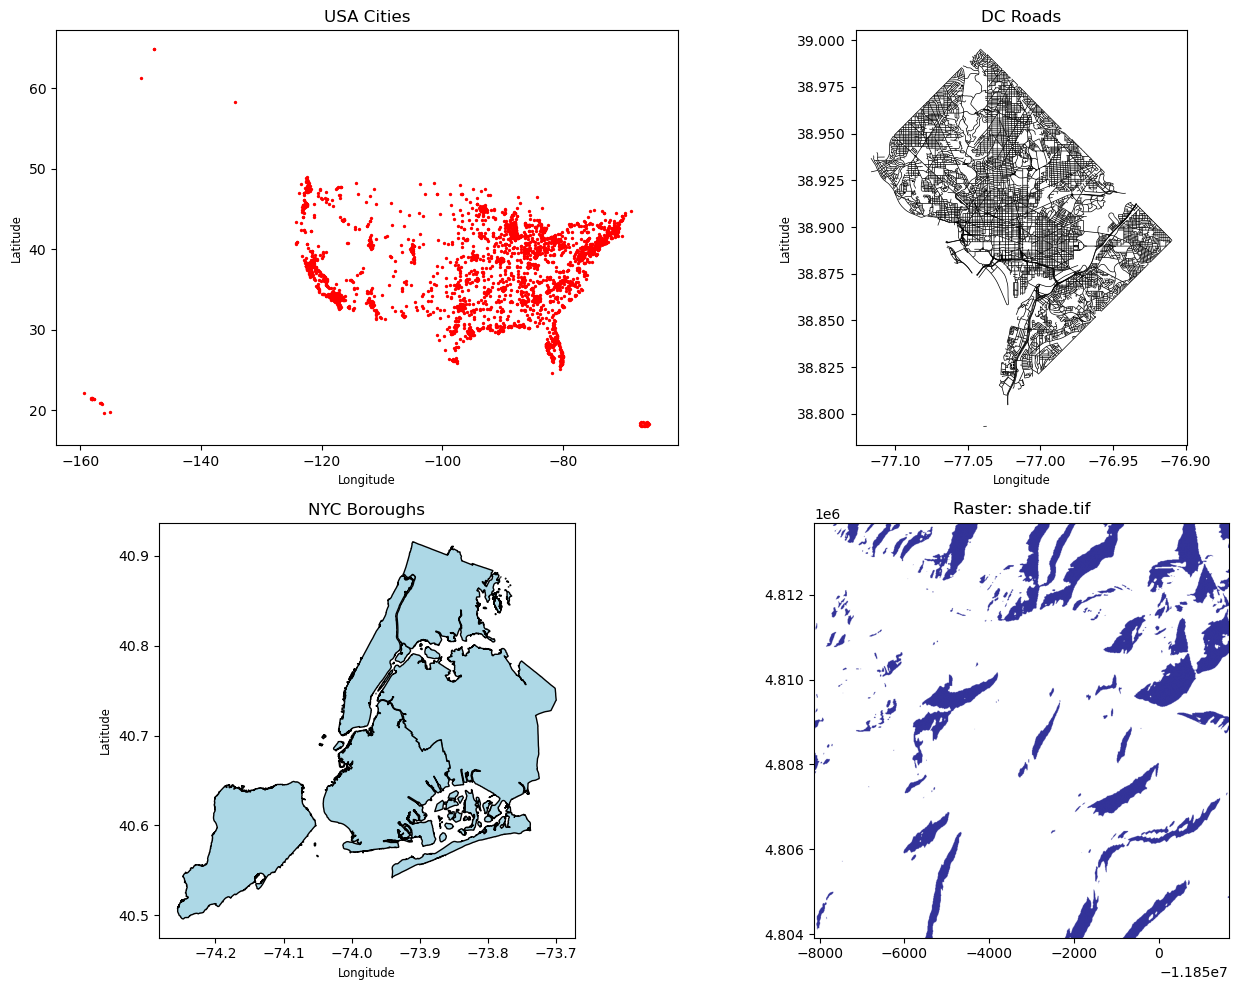

In [6]:
import matplotlib.pyplot as plt
import geopandas as gpd
import geoplot as gplt
import numpy as np
import rasterio
from rasterio.plot import show

# TODO:
# 1. Vykreslite nasledujuce datasety na grafe
#   - usa_cities, dc_roads, nyc_boroughs z knižnice geoplot
#   - 'https://github.com/rasterio/rasterio/raw/main/tests/data/shade.tif' pomocou rasterio.open


import matplotlib.pyplot as plt
import geopandas as gpd
import geoplot as gplt
import numpy as np
import rasterio
from rasterio.plot import show

# 1. Načítanie datasetov z knižnice geoplot
usa_cities = gpd.read_file(
    gplt.datasets.get_path("usa_cities")
)

dc_roads = gpd.read_file(
    gplt.datasets.get_path("dc_roads")
)

nyc_boroughs = gpd.read_file(
    gplt.datasets.get_path("nyc_boroughs")
)

# 2. Otvorenie rasterového súboru
url = "https://github.com/rasterio/rasterio/raw/main/tests/data/shade.tif"

with rasterio.open(url) as src:
    raster = src.read(1)

    # 3. Vytvorenie grafov
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # USA – mestá
    usa_cities.plot(
        ax=axes[0, 0],
        markersize=2,
        color="red"
    )
    axes[0, 0].set_title("USA Cities")
    axes[0, 0].set_xlabel("Longitude")
    axes[0, 0].set_ylabel("Latitude")

    # Washington, D.C. – cesty
    dc_roads.plot(
        ax=axes[0, 1],
        color="black",
        linewidth=0.5
    )
    axes[0, 1].set_title("DC Roads")
    axes[0, 1].set_xlabel("Longitude")
    axes[0, 1].set_ylabel("Latitude")

    # New York City – mestské časti
    nyc_boroughs.plot(
        ax=axes[1, 0],
        edgecolor="black",
        color="lightblue"
    )
    axes[1, 0].set_title("NYC Boroughs")
    axes[1, 0].set_xlabel("Longitude")
    axes[1, 0].set_ylabel("Latitude")

    # Rasterový súbor shade.tif
    show(
        raster,
        transform=src.transform,
        ax=axes[1, 1],
        cmap="terrain"
    )
    axes[1, 1].set_title("Raster: shade.tif")

    plt.tight_layout()
    plt.show()


* **Reprojekcia CRS**: 
  * Prevod súradníc z uhlových stupňov GPS (WGS 84) do metrického systému, aby sme mohli počítať reálne vzdialenosti a plochy v metroch.

* **Buffer (Obalová zóna)**:
  * Vytvorenie plošného polygónu okolo bodu, línie alebo plochy v zadanom polomere.

* **Intersection / Prienik**: 
  * Geometrické orezanie dvoch vrstiev, ktoré zachová iba územie, kde sa obe vrstvy navzájom prekrývajú.

* **Spatial Join**: 
  * Priestorový VLOOKUP, ktorý prepojí dve tabuľky na základe toho, či do seba ich geometrie v priestore fyzicky spadajú.

* **Change of Spatial Support (Zmena supportu)**: 
  * Zmena geometrickej mierky dát – napríklad agregácia tisícov izolovaných bodov do plošného súhrnu za celé polygóny.

* **MAUP (Modifiable Areal Unit Problem)**: 
  * Štatistické skreslenie, pri ktorom výsledky analýzy zásadne závisia od toho, aké veľké a aké tvary hraníc zvolíme pre agregáciu dát.


Pôvodné CRS:
NYC Boroughs: EPSG:4326
NYC Collisions: EPSG:4326

Odhadnuté UTM CRS:
Boroughs: EPSG:32618
Collisions: EPSG:32618

Nové CRS:
EPSG:32618
EPSG:32618


C:\Users\Anna\AppData\Local\Temp\ipykernel_11304\963541146.py:70: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  area_original = manhattan_original.geometry.area.sum()



Plocha Manhattanu:
Pôvodné CRS: 0.006307 (štvorcové stupne)
UTM 18N: 59.09 km²

Vzdialenosť Times Square -> Wall Street:
Pôvodné CRS: 0.056176 stupňov
UTM 18N: 5983.31 metrov
UTM 18N: 5.98 km


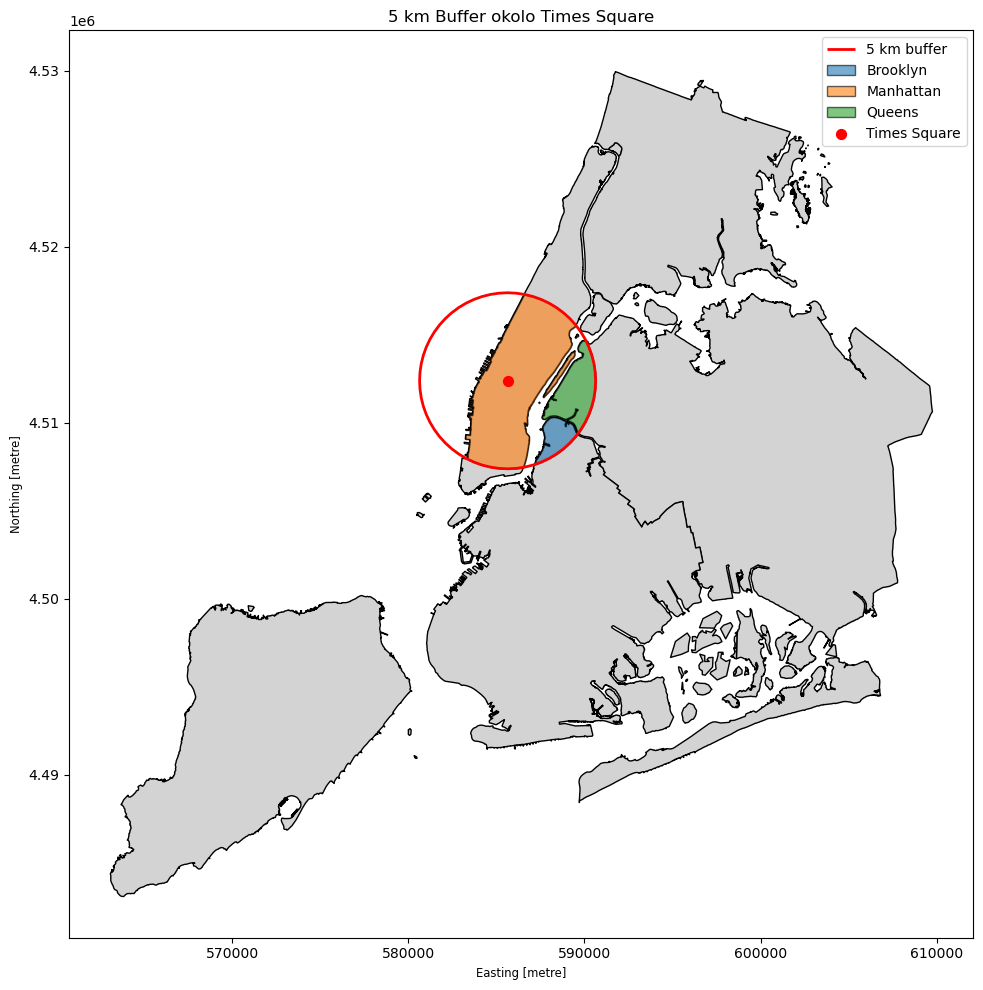


Plocha pevniny v 5 km buffri:
BoroName
Brooklyn      3.308
Manhattan    33.829
Queens        7.799
Name: area_km2, dtype: float64

Počet nehôd podľa mestských častí:
BoroName
Bronx             582
Brooklyn         2416
Manhattan        1611
Queens           2433
Staten Island     256
dtype: int64


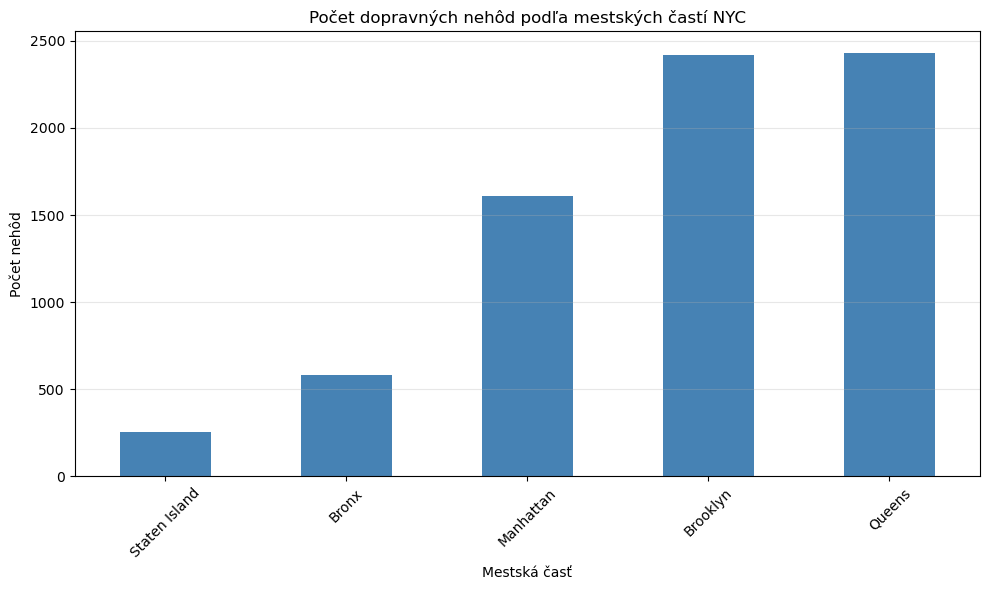


Hustota dopravných nehôd:
               accidents  area_km2  accidents_per_km2
BoroName                                             
Bronx                582    110.20               5.28
Brooklyn            2416    181.93              13.28
Manhattan           1611     59.09              27.26
Queens              2433    283.19               8.59
Staten Island        256    150.76               1.70


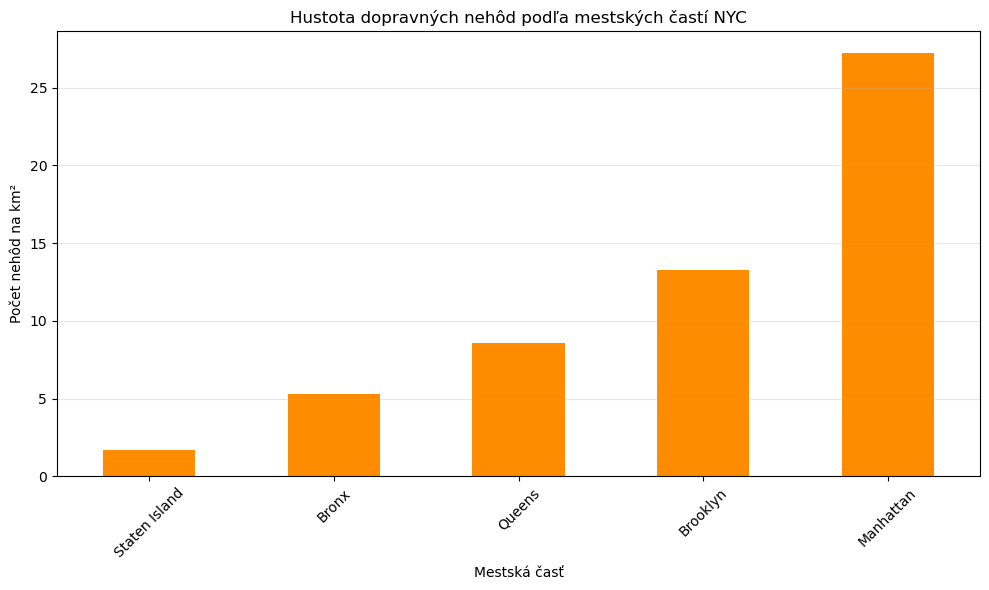

In [3]:
# TODO:
# 1. Načítanie dát a kontrola CRS:
#    - Načítajte polygóny mestských častí (nyc_boroughs) a body nehôd (nyc_collision_factors) cez geoplot
#    - Skontrolujte ich pôvodné CRS (.crs)
#    - Reprojektujte obe vrstvy do metrického systému UTM zóna 18N (EPSG:32618) pomocou .estimate_utm_crs() a .to_crs()
#    - Porovnajte výpočet plochy Manhattanu (.area) a výpočet vzdialenosti (.distance) Times Square -> Wall Street 
#       na pôvodných a reprojektovaných dátach
#
# 2. Intersection a Sjoin:
#    - Vytvorte referenčný bod pre Times Square (lon=-73.9855, lat=40.7580) v EPSG:4326 a reprojektujte do UTM 18N
#    - Vytvorte 5 km zónu pomocou .buffer()
#    - Pomocou gpd.overlay({data}, {buffer}, how='intersection') orežte kruh na skutočnú pevninu NYC a vykreslite výsledok na grafe
#    - Vypíšte rozlohu pevniny v kruhu pre jednotlivé mestské časti (Manhattan, Queens, Brooklyn)
#    - Spojte body nehôd so štvrťami pomocou gpd.sjoin(..., predicate='within')
#    - Agregujte celkový počet nehôd podľa štvrtí (groupby('BoroName').size()) a vykreslite výsledok na grafe
#    - Vypočítajte hustotu nehôd na km² pre všetky štvrte a vykreslite výsledok na grafe

import geopandas as gpd
import geoplot as gplt
import matplotlib.pyplot as plt
import pandas as pd
from shapely.geometry import Point

# ==========================================
# 1. NAČÍTANIE DÁT A KONTROLA CRS
# ==========================================

# Načítanie datasetov
nyc_boroughs = gpd.read_file(
    gplt.datasets.get_path("nyc_boroughs")
)

nyc_collision_factors = gpd.read_file(
    gplt.datasets.get_path("nyc_collision_factors")
)

# Kontrola pôvodného CRS
print("Pôvodné CRS:")
print("NYC Boroughs:", nyc_boroughs.crs)
print("NYC Collisions:", nyc_collision_factors.crs)

# Odhad vhodného UTM CRS
print("\nOdhadnuté UTM CRS:")
print("Boroughs:", nyc_boroughs.estimate_utm_crs())
print("Collisions:", nyc_collision_factors.estimate_utm_crs())

# Reprojekcia do UTM zóny 18N
nyc_boroughs_utm = nyc_boroughs.to_crs(epsg=32618)
nyc_collision_factors_utm = nyc_collision_factors.to_crs(epsg=32618)

print("\nNové CRS:")
print(nyc_boroughs_utm.crs)
print(nyc_collision_factors_utm.crs)


# ==========================================
# 2. POROVNANIE PLOCHY A VZDIALENOSTI
# ==========================================

# Výber Manhattanu
manhattan_original = nyc_boroughs[
    nyc_boroughs["BoroName"] == "Manhattan"
]

manhattan_utm = nyc_boroughs_utm[
    nyc_boroughs_utm["BoroName"] == "Manhattan"
]

# Výpočet plochy
area_original = manhattan_original.geometry.area.sum()
area_utm = manhattan_utm.geometry.area.sum()

print("\nPlocha Manhattanu:")
print(f"Pôvodné CRS: {area_original:.6f} (štvorcové stupne)")
print(f"UTM 18N: {area_utm / 1_000_000:.2f} km²")


# Vytvorenie bodov Times Square a Wall Street
times_square = Point(-73.9855, 40.7580)
wall_street = Point(-74.0099, 40.7074)

# Vzdialenosť v pôvodnom CRS
distance_original = times_square.distance(wall_street)

# Vytvorenie GeoSeries v EPSG:4326
locations = gpd.GeoSeries(
    [times_square, wall_street],
    crs="EPSG:4326"
)

# Reprojekcia do UTM 18N
locations_utm = locations.to_crs(epsg=32618)

# Vzdialenosť v metroch
distance_utm = locations_utm.iloc[0].distance(
    locations_utm.iloc[1]
)

print("\nVzdialenosť Times Square -> Wall Street:")
print(f"Pôvodné CRS: {distance_original:.6f} stupňov")
print(f"UTM 18N: {distance_utm:.2f} metrov")
print(f"UTM 18N: {distance_utm / 1000:.2f} km")


# ==========================================
# 3. BUFFER A INTERSECTION
# ==========================================

# Referenčný bod Times Square v EPSG:4326
times_square_gdf = gpd.GeoDataFrame(
    {"name": ["Times Square"]},
    geometry=[times_square],
    crs="EPSG:4326"
)

# Reprojekcia do UTM 18N
times_square_utm = times_square_gdf.to_crs(epsg=32618)

# Vytvorenie 5 km bufferu
buffer_5km = times_square_utm.copy()
buffer_5km["geometry"] = buffer_5km.geometry.buffer(5000)

# Prienik bufferu s mestskými časťami NYC
intersection = gpd.overlay(
    nyc_boroughs_utm,
    buffer_5km,
    how="intersection"
)

# Vykreslenie výsledku
fig, ax = plt.subplots(figsize=(10, 10))

nyc_boroughs_utm.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black"
)

buffer_5km.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2,
    label="5 km buffer"
)

intersection.plot(
    ax=ax,
    column="BoroName",
    legend=True,
    alpha=0.6,
    edgecolor="black"
)

times_square_utm.plot(
    ax=ax,
    color="red",
    markersize=50,
    label="Times Square"
)

ax.set_title("5 km Buffer okolo Times Square")
ax.legend()
plt.tight_layout()
plt.show()


# ==========================================
# 4. PLOCHA PEvnINY V BUFFERI PODĽA ŠTVRTÍ
# ==========================================

# Výpočet plochy prieniku podľa mestských častí
intersection["area_km2"] = (
    intersection.geometry.area / 1_000_000
)

area_by_borough = (
    intersection.groupby("BoroName")["area_km2"]
    .sum()
)

print("\nPlocha pevniny v 5 km buffri:")
print(area_by_borough.round(3))


# ==========================================
# 5. SPATIAL JOIN – PRIRADENIE NEHÔD K ŠTVRTIAM
# ==========================================

# Priestorové spojenie bodov nehôd s polygónmi
collisions_joined = gpd.sjoin(
    nyc_collision_factors_utm,
    nyc_boroughs_utm[["BoroName", "geometry"]],
    how="inner",
    predicate="within"
)

# Počet nehôd podľa mestských častí
collisions_count = (
    collisions_joined
    .groupby("BoroName")
    .size()
)

print("\nPočet nehôd podľa mestských častí:")
print(collisions_count)


# ==========================================
# 6. VIZUALIZÁCIA POČTU NEHÔD
# ==========================================

collisions_count.sort_values().plot(
    kind="bar",
    figsize=(10, 6),
    color="steelblue"
)

plt.title("Počet dopravných nehôd podľa mestských častí NYC")
plt.xlabel("Mestská časť")
plt.ylabel("Počet nehôd")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# 7. HUSTOTA NEHÔD NA KM²
# ==========================================

# Výpočet plochy všetkých mestských častí
borough_areas = (
    nyc_boroughs_utm.copy()
)

borough_areas["area_km2"] = (
    borough_areas.geometry.area / 1_000_000
)

borough_areas = (
    borough_areas.groupby("BoroName")["area_km2"]
    .sum()
)

# Spojenie počtu nehôd a plochy
density = pd.DataFrame({
    "accidents": collisions_count,
    "area_km2": borough_areas
})

# Mestské časti bez nehôd dostanú počet 0
density["accidents"] = density["accidents"].fillna(0)

# Výpočet hustoty nehôd
density["accidents_per_km2"] = (
    density["accidents"] / density["area_km2"]
)

print("\nHustota dopravných nehôd:")
print(density.round(2))


# ==========================================
# 8. VIZUALIZÁCIA HUSTOTY NEHÔD
# ==========================================

density["accidents_per_km2"].sort_values().plot(
    kind="bar",
    figsize=(10, 6),
    color="darkorange"
)

plt.title("Hustota dopravných nehôd podľa mestských častí NYC")
plt.xlabel("Mestská časť")
plt.ylabel("Počet nehôd na km²")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Priestorová autokorelácia

Miera toho, či sa podobné hodnoty v priestore zhlukujú (napr. bohaté štvrte vedľa bohatých), alebo sú rozmiestnené náhodne.

![Typy priestorovej autokorelácie](imgs/spatial_autocorrelation_types.png)


* **Negatívna** autokorelácia: Susedia vykazujú systematicky odlišné hodnoty – vysoké hodnoty sú obklopené nízkymi a naopak.
* **Žiadna** autokorelácia: Hodnoty sú rozmiestnené náhodne - priestorová nezávislosť.
* **Pozitívna** autokorelácia: Podobné hodnoty sa zhlukujú vedľa seba.

---

### Globálna priestorová autokorelácia a Globálne Moranovo $I$
Meria lineárnu závislosť medzi hodnotou v lokalite ($y$) a priemernou hodnotou u jej susedov ($Wy$):
* **$I > 0$ (do $+1$):** Pozitívna autokorelácia — podobné hodnoty sa zhlukujú (vysoké s vysokými, nízke s nízkymi).
* **$I \approx 0$:** Nulová autokorelácia — priestorová náhodnosť, hodnoty sú rozmiestnené nezávisle bez akéhokoľvek vzoru.
* **$I < 0$ (do $-1$, vľavo):** Negatívna autokorelácia — šachovnicové striedanie, kde susedia majú systematicky opačné hodnoty.

---

### Lokálna priestorová autokorelácia a Lokálne Moranovo $I$
Lokálne Moranovo $I$ sa počíta pre každú jednotlivú lokalitu, vďaka čomu identifikuje konkrétne územia, ktoré významne prispievajú k celkovej priestorovej autokorelácii. 

Zatrieďuje štatisticky významné lokality ($p < 0.05$) do 4 typov (kvadrantov):

* **HH (High-High) – Hotspot:** Vysoká hodnota obklopená vysokými hodnotami (napr. štvrť s vysokou kriminalitou uprostred iných nebezpečných štvrtí).
* **LL (Low-Low) – Coldspot:** Nízka hodnota obklopená nízkymi hodnotami (napr. pokojná, bezpečná rezidenčná zóna).
* **HL (High-Low) – Priestorový outlier:** Vysoká hodnota obklopená nízkymi hodnotami (ojedinelé problematické ohnisko v inak pokojnom regióne).
* **LH (Low-High) – Priestorový outlier:** Nízka hodnota obklopená vysokými hodnotami (bezpečná enkláva obklopená vysokou kriminalitou).


Počet záznamov: 49
   AREA  PERIMETER  COLUMBUS_  COLUMBUS_I  POLYID  NEIG  HOVAL    INC  CRIME  \
0  0.31       2.44          2           5       1     5  80.47  19.53  15.73   
1  0.26       2.24          3           1       2     1  44.57  21.23  18.80   
2  0.19       2.19          4           6       3     6  26.35  15.96  30.63   
3  0.08       1.43          5           2       4     2  33.20   4.48  32.39   
4  0.49       3.00          6           7       5     7  23.23  11.25  50.73   

   OPEN  ...  DISCBD      X      Y  NSA  NSB  EW  CP  THOUS  NEIGNO  \
0  2.85  ...    5.03  38.80  44.07    1    1   1   0   1000    1005   
1  5.30  ...    4.27  35.62  42.38    1    1   0   0   1000    1001   
2  4.53  ...    3.89  39.82  41.18    1    1   1   0   1000    1006   
3  0.39  ...    3.70  36.50  40.52    1    1   0   0   1000    1002   
4  0.41  ...    2.83  40.01  38.00    1    1   1   0   1000    1007   

              geometry  
0   POINT (38.8 44.07)  
1  POINT (35.62 42.38) 

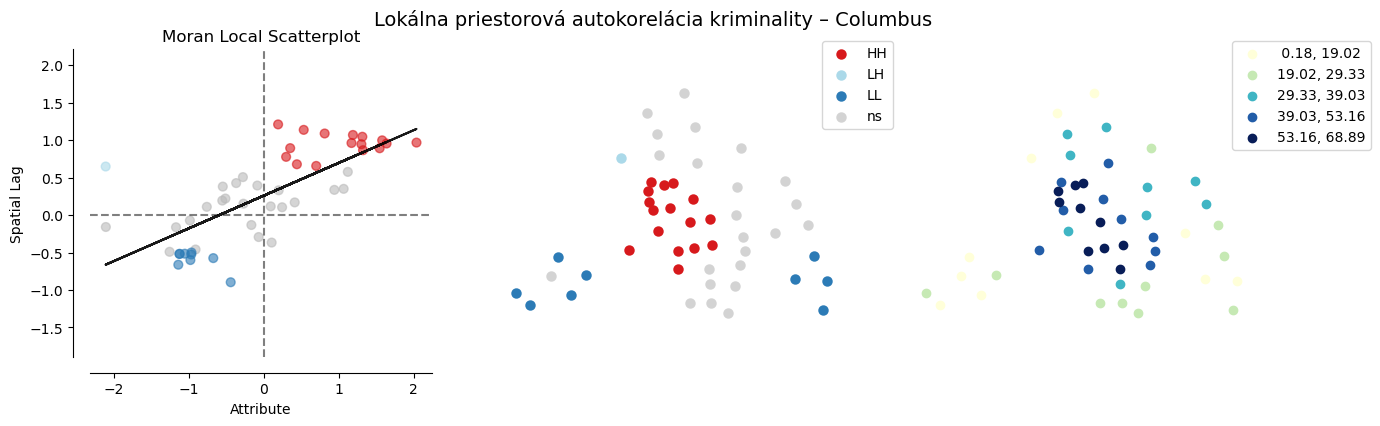


ROZDELENIE LISA ZHLUKOV
------------------------
cluster_name
Not significant    23
High-High          16
Low-Low             9
Low-High            1
Name: count, dtype: int64

INTERPRETÁCIA LISA
-------------------
Hotspot (High-High): 16
Coldspot (Low-Low): 9
Spatial outliers: 1

Štatisticky významné oblasti:
    POLYID  CRIME   local_I  p_value cluster_name
29      30  68.89  1.932438    0.002    High-High
10      11  62.28  1.534322    0.002    High-High
24      25  61.30  1.544490    0.002    High-High
28      29  60.75  1.351655    0.004    High-High
13      14  57.07  1.123810    0.003    High-High
27      28  56.92  1.347677    0.002    High-High
11      12  56.71  1.207986    0.002    High-High
15      16  54.84  1.246931    0.002    High-High
18      19  54.52  1.103231    0.002    High-High
14      15  48.59  0.867041    0.002    High-High
12      13  46.72  0.449962    0.015    High-High
17      18  43.96  0.594149    0.002    High-High
36      37  42.45  0.293733    0.023

In [9]:

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from esda.moran import Moran, Moran_Local
from libpysal.weights import KNN
from splot.esda import plot_local_autocorrelation

# ==========================================
# 1. NAČÍTANIE DÁT A PRÍPRAVA GEODATAFRAME
# ==========================================

DATA_URL = (
    "https://raw.githubusercontent.com/GeoDaCenter/GeoDaSpace/master/"
    "econometrics/examples/columbus.csv"
)

FULL_COLUMNS = [
    "AREA", "PERIMETER", "COLUMBUS_", "COLUMBUS_I",
    "POLYID", "NEIG", "HOVAL", "INC", "CRIME",
    "OPEN", "PLUMB", "DISCBD", "X", "Y",
    "NSA", "NSB", "EW", "CP", "THOUS", "NEIGNO"
]

# Načítanie CSV
df = pd.read_csv(
    DATA_URL,
    skiprows=1,
    header=None,
    names=FULL_COLUMNS
)

# Vytvorenie bodovej geometrie
geometry = gpd.points_from_xy(df["X"], df["Y"])

# Vytvorenie GeoDataFrame
columbus_gdf = gpd.GeoDataFrame(
    df,
    geometry=geometry
)

print("Počet záznamov:", len(columbus_gdf))
print(columbus_gdf.head())


# ==========================================
# 2. PRIETOROVÉ VÁHY – KNN
# ==========================================

weights = KNN.from_dataframe(
    columbus_gdf,
    k=8
)

# Riadková normalizácia
weights.transform = "R"

print("\nPočet susedov:", weights.n)
print("Normalizácia:", weights.transform)


# ==========================================
# 3. GLOBÁLNE MORANOVO I
# ==========================================

crime = columbus_gdf["CRIME"].values

moran_global = Moran(
    crime,
    weights,
    permutations=999
)

print("\nGLOBÁLNE MORANOVO I")
print("--------------------")

print("Moranovo I:", round(moran_global.I, 4))
print("P-hodnota:", round(moran_global.p_sim, 4))

if moran_global.p_sim < 0.05:
    print("Výsledok je štatisticky významný.")

    if moran_global.I > 0:
        print("Existuje pozitívna priestorová autokorelácia.")
        print("Podobné hodnoty kriminality sa zhlukujú.")
    else:
        print("Existuje negatívna priestorová autokorelácia.")
        print("Susedné oblasti majú tendenciu mať odlišné hodnoty.")
else:
    print("Výsledok nie je štatisticky významný.")
    print("Nemáme dostatok dôkazov o priestorovom zhlukovaní.")


# ==========================================
# 4. LOKÁLNE MORANOVO I (LISA)
# ==========================================

moran_local = Moran_Local(
    crime,
    weights,
    permutations=999
)

columbus_gdf["local_I"] = moran_local.Is
columbus_gdf["p_value"] = moran_local.p_sim
columbus_gdf["cluster"] = moran_local.q

# Štatistická významnosť
significant = columbus_gdf["p_value"] < 0.05

print("\nLOKÁLNE MORANOVO I")
print("--------------------")
print("Počet štatisticky významných oblastí:", significant.sum())


# ==========================================
# 5. VIZUALIZÁCIA LISA
# ==========================================

plot_local_autocorrelation(
    moran_local,
    columbus_gdf,
    "CRIME",
    p=0.05
)

plt.suptitle(
    "Lokálna priestorová autokorelácia kriminality – Columbus",
    fontsize=14
)

plt.show()


# ==========================================
# 6. VYHODNOTENIE LISA ZHLUKOV
# ==========================================

# 1 = High-High
# 2 = Low-High
# 3 = Low-Low
# 4 = High-Low

cluster_names = {
    1: "High-High",
    2: "Low-High",
    3: "Low-Low",
    4: "High-Low"
}

columbus_gdf["cluster_name"] = (
    columbus_gdf["cluster"].map(cluster_names)
)

# Nevýznamné oblasti
columbus_gdf.loc[
    ~significant,
    "cluster_name"
] = "Not significant"

print("\nROZDELENIE LISA ZHLUKOV")
print("------------------------")

print(columbus_gdf["cluster_name"].value_counts())


# ==========================================
# 7. INTERPRETÁCIA VÝSLEDKOV
# ==========================================

print("\nINTERPRETÁCIA LISA")
print("-------------------")

print(
    "Hotspot (High-High):",
    (columbus_gdf["cluster_name"] == "High-High").sum()
)

print(
    "Coldspot (Low-Low):",
    (columbus_gdf["cluster_name"] == "Low-Low").sum()
)

print(
    "Spatial outliers:",
    columbus_gdf["cluster_name"].isin(
        ["Low-High", "High-Low"]
    ).sum()
)

print("\nŠtatisticky významné oblasti:")

print(
    columbus_gdf.loc[
        significant,
        ["POLYID", "CRIME", "local_I", "p_value", "cluster_name"]
    ].sort_values(
        "CRIME",
        ascending=False
    )
)


## Priestorové modely: SLX, SAR, SEM a SDM

Keď OLS regresia vykazuje priestorovú autokoreláciu v rezíduách, nasadzujeme priestorové modely. Každý však rieši odlišný vecný mechanizmus:

| Model | Priestorová zložka | Mechanizmus | Kedy použiť |
| :--- | :--- | :--- | :--- | 
| **OLS** | Žiadna | Predpokladá, že rezíduá sú nezávislé. | Keď rezíduá nevykazujú priestorovú autokoreláciu (susedia sa neovplyvňujú). |
| **SLX** *(Spatial Lag of X)* | $WX$ (lagované prediktory) | K bežným vysvetľujúcim premenným ($X$) pridáva do regresie aj ich priestorové lagy u susedov ($WX$) | Pri lokálnom prelievaní vlastností susedov (napr. bohatstvo susedov vplýva na moju lokalitu). |
| **SAR** *(Spatial Lag)* | $Wy$ (lagovaný výsledok) | Do modelu pridáva priestorový lag samotnej závislej premennej ($Wy$). Analógia k autoregresným modelom (AR) v časových radoch. | Na rozdiel od SLX sa tu vplyvy neobmedzujú len na susedov, ale vďaka spätnej väzbe sa šíria cez celý systém  |
| **SEM** *(Spatial Error Model)* | $Wu$ (lagovaná chyba) | Nepozorované vplyvy a šoky sú priestorovo závislé. | Keď priestorovú štruktúru spôsobujú vynechané nepozorované faktory alebo spoločné šoky. |
| **SDM** *(Spatial Durbin Model)* | $Wy$ aj $WX$ | Používa sa spätná väzba medzi výsledkami aj charakteristiky susedov. | Keď pôsobí šírenie výsledku ($Wy$) aj vplyv charakteristík susedov ($WX$) súčasne. |



Prítomnosť priestorovej autokorelácie možno overiť Moranovým testom aplikovaným na rezíduá štandardnej OLS regresie. Tento všeobecný test nás však iba upozorní na existenciu priestorovej závislosti, ale neurčuje, ktorý konkrétny model zvoliť. Pre model s priestorovým lagom prediktorov (SLX) neexistuje špeciálny test; overuje sa klasickým $F$-testom lineárnych obmedzení porovnávajúcim model s lagmi $WX$ a bez nich.

Pre voľbu medzi modelom s priestorovým lagom výsledku (SAR) a modelom s priestorovou chybou (SEM) slúžia špecializované testy Lagrangeových multiplikátorov (LM testy), ktoré sa vyhodnocujú po odhade OLS. Ak je štatisticky významný iba klasický test LM(lag), volíme model SAR (priestorový lag). V opačnom prípade, ak je významný iba LM(error), je správnou voľbou model SEM (priestorová chyba).

### Postup výberu priestorového modelu

1. **Odhadneme OLS s diagnostikou**:
   - Ak **Moranovo I rezíduí nie je signifikantné** (\(p \geq 0.05\)) → nemáme dostatok dôkazov o priestorovej autokorelácii. **OLS môže byť postačujúci**.
   - Ak **je signifikantné** (\(p < 0.05\)) → rezíduá vykazujú priestorovú autokoreláciu a pomocou **LM testov** skúmame vhodný priestorový model.

2. **Rozhodovací strom podľa LM testov:**
   - **Ani jeden LM test nie je signifikantný** → OLS zostáva vhodným kandidátom.
   - **Signifikantný iba LM (lag)** → preferujeme **SAR** (priestorové oneskorenie \(Wy\)).
   - **Signifikantný iba LM (error)** → preferujeme **SEM** (priestorová chyba \(W\varepsilon\)).
   - **Signifikantné sú OBA** → skúmame **robustné LM testy**:
     - **Signifikantný iba Robust LM-lag** → preferujeme **SAR**.
     - **Signifikantný iba Robust LM-error** → preferujeme **SEM**.
     - **Oba robustné testy sú signifikantné** → zvážime komplexnejší priestorový model. Pri zjednodušenom výbere možno porovnať pôvodné LM testy a uprednostniť model s nižšou \(p\)-hodnotou.
     - **Ani jeden robustný test nie je signifikantný** → výsledok je nejednoznačný.

3. **Overenie vhodnosti vybraného modelu:**
   - Porovnáme AIC modelov OLS, SAR a SEM.
   - Skontrolujeme, či sa priestorová autokorelácia rezíduí znížila alebo odstránila.
   - Posúdime ekonomickú interpretáciu zvoleného modelu.


In [10]:
# TODO: 
#   1. Vytvorte OLS model pomocou závislej premennej CRIME, nezávislých premenných INC a HOVAL, 
#       a vytvorenej matice priestorových váh
#       - Povoľte priestorovú diagnostiku nastavením spat_diag=True
#       - Povoľte Moranov test rezíduí nastavením moran=True
#       - Nastavte popisné názvy (name_y, name_x, name_w, name_ds) pre prehľadný report
#
#   2. Zhodnoťte výber vhodného modelu pre naše dáta, podľa vyššie definovaného postupu
#      -  moran_res, lm_lag, lm_error, rlm_lag, rlm_error

from spreg import OLS
# Závislá premenná
y = columbus_gdf[["CRIME"]].values

# Nezávislé premenné
X = columbus_gdf[["INC", "HOVAL"]].values

# Vytvorenie OLS modelu s priestorovou diagnostikou
ols_model = OLS(
    y,
    X,
    w=weights,
    spat_diag=True,
    moran=True,
    name_y="CRIME",
    name_x=["INC", "HOVAL"],
    name_w="KNN 8 najbližších susedov",
    name_ds="Columbus"
)

# Výpis výsledkov modelu
print(ols_model.summary)


# ==========================================
# 2. SPATIAL DIAGNOSTICS
# ==========================================

print("\nPRIETOROVÁ DIAGNOSTIKA")
print("-----------------------")

print("\nMoranov test rezíduí:")
print(ols_model.moran_res)

print("\nLagrange Multiplier – Lag:")
print(ols_model.lm_lag)

print("\nLagrange Multiplier – Error:")
print(ols_model.lm_error)

print("\nRobust LM – Lag:")
print(ols_model.rlm_lag)

print("\nRobust LM – Error:")
print(ols_model.rlm_error)


# ==========================================
# 3. VYHODNOTENIE VHODNÉHO MODELU
# ==========================================

print("\nVYHODNOTENIE MODELU")
print("--------------------")

# Moranov test rezíduí
if ols_model.moran_res[1] < 0.05:
    print("Moranov test: rezíduá vykazujú priestorovú autokoreláciu.")
else:
    print("Moranov test: priestorová autokorelácia rezíduí nie je štatisticky významná.")

# Robustné LM testy
p_lag = ols_model.rlm_lag[1]
p_error = ols_model.rlm_error[1]

if p_lag < 0.05 and p_error >= 0.05:
    print("Odporúčaný model: Spatial Lag Model (SAR).")

elif p_error < 0.05 and p_lag >= 0.05:
    print("Odporúčaný model: Spatial Error Model (SEM).")

elif p_lag < 0.05 and p_error < 0.05:
    print("Oba robustné testy sú štatisticky významné.")
    print("Je potrebné porovnať SAR a SEM model, prípadne zvážiť SAC model.")

else:
    print("Robustné LM testy nie sú štatisticky významné.")
    print("OLS model môže byť postačujúci, ak neexistujú ďalšie diagnostické problémy.")


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :    Columbus
Weights matrix      :KNN 8 najbližších susedov
Dependent Variable  :       CRIME                Number of Observations:          49
Mean dependent var  :     35.1298                Number of Variables   :           3
S.D. dependent var  :     16.7321                Degrees of Freedom    :          46
R-squared           :      0.5525
Adjusted R-squared  :      0.5330
Sum squared residual:     6014.21                F-statistic           :     28.3918
Sigma-square        :     130.744                Prob(F-statistic)     :   9.315e-09
S.E. of regression  :      11.434                Log likelihood        :    -187.374
Sigma-square ML     :     122.739                Akaike info criterion :     380.749
S.E of regression ML:     11.0788                Schwarz criterion     :     386.424

----

## Priestorová krížová validácia a predikcia so SAR modelom

Priestorovo blízke pozorovania často vykazujú podobné hodnoty v dôsledku priestorovej autokorelácie. Náhodné delenie preto môže viesť k príliš optimistickému odhadu predikčnej schopnosti modelu na geograficky nepozorovaných územiach. - Spatial Data Leakage.

Riešením je priestorová bloková krížová validácia:
1. Územie rozdelíme do ucelených geografických blokov (napr. 4 kvadranty mesta: NW, NE, SW, SE).
2. V každom kole natrénujeme model na 3 blokoch a otestujeme jeho predikčnú schopnosť na 4. (geograficky oddelenom) bloku.

Knižnica `spreg` neponúka štandardnú metódu `.predict()`, pretože predikcia priestorového autoregresného modelu nie je obyčajné $X\beta$. Predikovaná hodnota závisí aj od priestorového spilloveru a väzieb na okolie:

$$\hat{y}_{test} = (I - \rho W_{TT})^{-1} \big(X_{test}\beta + \rho W_{TR} y_{train}\big)$$

* **$X_{test}\beta$**: Priamy vplyv vlastností lokality (príjem `INC`, hodnota domov `HOVAL`).
* **$\rho W_{TR} y_{train}$**: Priestorový vplyv, ktorý preteká cez hranicu z tréningového okolia, kde skutočné hodnoty $y_{train}$ poznáme.
* **$(I - \rho W_{TT})^{-1}$**: Priestorový multiplikátor vzájomného ovplyvňovania sa lokalít vnútri testovacieho územia.



Počet pozorovaní: 49

Medián X: 39.61
Medián Y: 31.91

Počet pozorovaní v jednotlivých kvadrantoch:
block
NW    14
SE    14
NE    11
SW    10
Name: count, dtype: int64
ML_Lag

========== TESTOVACÍ BLOK: NW ==========
Počet tréningových pozorovaní: 35
Počet testovacích pozorovaní: 14
Rho: 0.4635
Beta koeficienty: [ 4.13770382e+01 -1.53033398e+00 -4.41245920e-03]
RMSE: 16.43
ML_Lag

========== TESTOVACÍ BLOK: NE ==========
Počet tréningových pozorovaní: 38
Počet testovacích pozorovaní: 11
Rho: 0.7072
Beta koeficienty: [27.82737053 -0.20238235 -0.44542202]
RMSE: 16.82
ML_Lag

========== TESTOVACÍ BLOK: SW ==========
Počet tréningových pozorovaní: 39
Počet testovacích pozorovaní: 10
Rho: 0.3755
Beta koeficienty: [46.85556665 -1.06713675 -0.2629863 ]
RMSE: 10.96
ML_Lag

========== TESTOVACÍ BLOK: SE ==========
Počet tréningových pozorovaní: 35
Počet testovacích pozorovaní: 14
Rho: 0.4931
Beta koeficienty: [39.66525651 -0.97081344 -0.24676842]
RMSE: 8.47


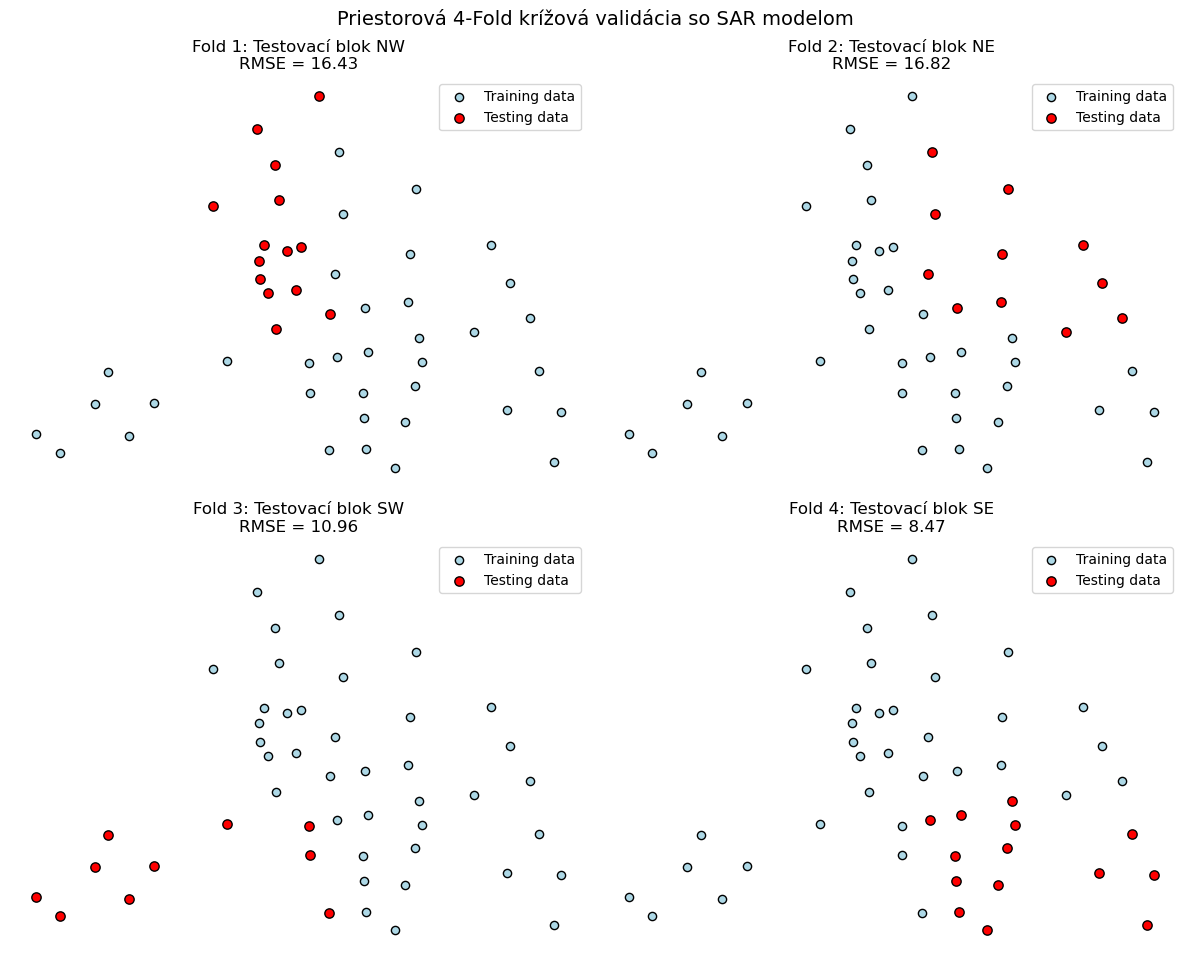


TABUĽKA PREDIKCIÍ
------------------


,POLYID,block,CRIME,pred_crime_sar
0,1,NW,15.73,29.398527
1,2,NW,18.80,27.209051
2,3,NE,30.63,37.009576
3,4,NW,32.39,52.455896
4,5,NE,50.73,50.042563
5,6,NE,26.07,32.032997
6,7,NW,0.18,50.878768
7,8,NW,38.43,47.335940
8,9,NE,30.52,34.894596
9,10,NE,34.00,-7.376086



Celkové RMSE: 13.63

PRIEMERNÉ RMSE CEZ 4 FOLDY:
13.17


In [12]:

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import libpysal

from spreg import ML_Lag


# ==========================================
# NAČÍTANIE DÁT
# ==========================================

DATA_URL = (
    "https://raw.githubusercontent.com/GeoDaCenter/GeoDaSpace/master/"
    "econometrics/examples/columbus.csv"
)

FULL_COLUMNS = [
    "AREA", "PERIMETER", "COLUMBUS_", "COLUMBUS_I",
    "POLYID", "NEIG", "HOVAL", "INC", "CRIME",
    "OPEN", "PLUMB", "DISCBD", "X", "Y",
    "NSA", "NSB", "EW", "CP", "THOUS", "NEIGNO"
]

df = pd.read_csv(
    DATA_URL,
    skiprows=1,
    header=None,
    names=FULL_COLUMNS
)

geometry = gpd.points_from_xy(df["X"], df["Y"])

data = gpd.GeoDataFrame(
    df,
    geometry=geometry
).reset_index(drop=True)

print("Počet pozorovaní:", len(data))


# ==========================================
# POMOCNÉ FUNKCIE PRE PREDIKCIU
# ==========================================

def predict_ols(betas, X_test):
    X = np.column_stack([np.ones(len(X_test)), X_test])
    return (X @ betas).flatten()


# OPRAVENÁ FUNKCIA SAR
def predict_sar(rho, betas, X_test, W_TT, W_TR, y_train):

    X = np.column_stack([np.ones(len(X_test)), X_test])

    # Obe časti musia mať rozmer (n, 1)
    X_beta = (X @ betas.reshape(-1, 1))

    spatial_effect = rho * (W_TR @ y_train.reshape(-1, 1))

    return np.linalg.solve(
        np.eye(len(X_test)) - rho * W_TT,
        X_beta + spatial_effect
    ).flatten()


# ==========================================
# TODO 1: ROZDELENIE MESTA NA KVADRANTY
# ==========================================

med_x = data["X"].median()
med_y = data["Y"].median()

print("\nMedián X:", med_x)
print("Medián Y:", med_y)


def assign_quadrant(row):

    if row["X"] >= med_x and row["Y"] >= med_y:
        return "NE"

    elif row["X"] < med_x and row["Y"] >= med_y:
        return "NW"

    elif row["X"] >= med_x and row["Y"] < med_y:
        return "SE"

    else:
        return "SW"


data["block"] = data.apply(assign_quadrant, axis=1)

blocks = ["NW", "NE", "SW", "SE"]

print("\nPočet pozorovaní v jednotlivých kvadrantoch:")
print(data["block"].value_counts())


# Stĺpec na uloženie predikcií
data["pred_crime_sar"] = np.nan


# ==========================================
# PRIESTOROVÉ VÁHY PRE CELÉ MESTO
# ==========================================

w_full = libpysal.weights.KNN.from_dataframe(
    data,
    k=4
)

w_full.transform = "R"

W = w_full.sparse.tocsr()


# ==========================================
# TODO 2–7: 4-FOLD CROSS-VALIDATION
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes = axes.flatten()

rmse_values = []


for i, (ax, b) in enumerate(zip(axes, blocks), 1):

    # --------------------------------------
    # TODO 2: TRAIN / TEST
    # --------------------------------------

    train = data[data["block"] != b]
    test = data[data["block"] == b]

    train_idx = train.index.to_numpy()
    test_idx = test.index.to_numpy()

    # --------------------------------------
    # TODO 3: KNN VÁHY PRE TRAINING
    # --------------------------------------

    w_train = libpysal.weights.KNN.from_dataframe(
        train,
        k=4
    )

    w_train.transform = "R"

    y_train = train["CRIME"].values
    X_train = train[["INC", "HOVAL"]].values

    # --------------------------------------
    # TODO 4: SAR MODEL
    # --------------------------------------

    sar_fold = ML_Lag(
        y_train.reshape(-1, 1),
        X_train,
        w=w_train,
        name_y="CRIME",
        name_x=["INC", "HOVAL"],
        name_w="KNN 4",
        name_ds=f"Columbus training fold {b}"
    )

    # Extrakcia rho a beta koeficientov
    rho = float(sar_fold.betas[-1, 0])
    betas = sar_fold.betas[:-1].flatten()

    # --------------------------------------
    # TODO 5: VÝPIS KOEFICIENTOV
    # --------------------------------------

    print(f"\n========== TESTOVACÍ BLOK: {b} ==========")

    print("Počet tréningových pozorovaní:", len(train))
    print("Počet testovacích pozorovaní:", len(test))

    print("Rho:", round(rho, 4))
    print("Beta koeficienty:", betas)

    # --------------------------------------
    # BLOKOVÉ ROZDELENIE MATICE VÁH
    # --------------------------------------

    W_TT = W[test_idx, :][:, test_idx].toarray()

    W_TR = W[test_idx, :][:, train_idx].toarray()

    X_test = test[["INC", "HOVAL"]].values

    # --------------------------------------
    # TODO 6: PREDIKCIA SAR
    # --------------------------------------

    y_pred = predict_sar(
        rho,
        betas,
        X_test,
        W_TT,
        W_TR,
        y_train
    )

    # Kontrola rozmerov
    assert len(y_pred) == len(test), (
        "Počet predikcií sa nezhoduje s počtom testovacích pozorovaní."
    )

    # Uloženie predikcií
    data.loc[test_idx, "pred_crime_sar"] = y_pred

    # --------------------------------------
    # RMSE PRE AKTUÁLNY BLOK
    # --------------------------------------

    rmse_fold = np.sqrt(
        np.mean(
            (test["CRIME"].values - y_pred) ** 2
        )
    )

    rmse_values.append(rmse_fold)

    print(f"RMSE: {rmse_fold:.2f}")

    # --------------------------------------
    # TODO 7: VIZUALIZÁCIA TRAIN / TEST
    # --------------------------------------

    train.plot(
        ax=ax,
        color="lightblue",
        edgecolor="black",
        markersize=35,
        label="Training data"
    )

    test.plot(
        ax=ax,
        color="red",
        edgecolor="black",
        markersize=45,
        label="Testing data"
    )

    ax.set_title(
        f"Fold {i}: Testovací blok {b}\nRMSE = {rmse_fold:.2f}"
    )

    ax.legend()
    ax.set_axis_off()


plt.suptitle(
    "Priestorová 4-Fold krížová validácia so SAR modelom",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ==========================================
# TODO 8: TABUĽKA PREDIKCIÍ
# ==========================================

predictions_table = pd.DataFrame({
    "POLYID": data["POLYID"],
    "block": data["block"],
    "CRIME": data["CRIME"],
    "pred_crime_sar": data["pred_crime_sar"]
})

print("\nTABUĽKA PREDIKCIÍ")
print("------------------")

display(predictions_table.head(15))


# ==========================================
# CELKOVÉ RMSE
# ==========================================

overall_rmse = np.sqrt(
    np.mean(
        (data["CRIME"] - data["pred_crime_sar"]) ** 2
    )
)

print(f"\nCelkové RMSE: {overall_rmse:.2f}")

print("\nPRIEMERNÉ RMSE CEZ 4 FOLDY:")
print(f"{np.mean(rmse_values):.2f}")



#### Bonus 2B:

**Cieľ:** Preskúmať priestorovú závislosť dopravných nehôd medzi okrskami New Yorku a porovnať predikčnú schopnosť modelov OLS a SAR na geograficky oddelených testovacích dátach.

1. Príprava a agregácia dát podľa PSČ
  - Zoskupte dopravné nehody podľa poštových smerovacích čísel.
  - Pre každé PSČ vypočítajte celkový počet zaznamenaných nehôd.
  - Vytvorte cieľovú premennú podiel_np, ktorá vyjadruje podiel nehôd, pri ktorých bolo ako príčina uvedené nedanie prednosti v jazde.
  - Vytvorte vysvetľujúce premenné podiel_suv a podiel_taxiky, ktoré vyjadrujú podiel nehôd, pri ktorých bolo ako prvé zaznamenané vozidlo uvedené SUV alebo taxík.
  - Do ďalšej analýzy zahrňte iba oblasti PSČ s minimálne 8 zaznamenanými nehodami.
  - Pre každé PSČ vypočítajte priemernú zemepisnú šírku a dĺžku zaznamenaných nehôd a vytvorte bodový GeoDataFrame so súradnicovým systémom EPSG:4326. 
  - Rozdeľte PSČ podľa geografickej polohy na približne 80 % tréningových a 20 % testovacích pozorovaní.
  - Ako testovaciu množinu vyberte 20 % najvýchodnejšie položených oblastí podľa zemepisnej dĺžky (lon)
      * použite gdf['lon'].quantile(0.80) na určenie hranice
  - Vykreslite obe množiny na mape New Yorku a farebne ich odlíšte.

2. Konštrukcia priestorovej váhovej matice a predikcia s OLS a SAR
  - Reprojektujte bodové dáta do metrického súradnicového systému EPSG:32618.
  - Pomocou libpysal.weights.KNN vytvorte maticu 5 najbližších susedov (k=5) osobitne pre tréningové dáta a celé územie.
  - Vykonajte riadkovú štandardizáciu (transform='R').
  - Odhadnite OLS model pomocou spreg.OLS a SAR model pomocou spreg.ML_Lag.
  - Pomocou pripravených funkcií predict_ols() a predict_sar() vypočítajte predikované hodnoty pre testovacie oblasti.
  - Porovnajte skutočné a predikované hodnoty v tabuľke a grafe.
  - Určte, ktorý model dosiahol nižšiu predikčnú chybu.

In [19]:
import os, glob
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from libpysal.weights import KNN
from spreg import OLS, ML_Lag
import kagglehub

In [20]:
KAGGLE_DATASET = "mysarahmadbhat/nyc-traffic-accidents"
path = kagglehub.dataset_download(KAGGLE_DATASET)
csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("Súbory:", csv_files)
CSV_PATH = max(csv_files, key=os.path.getsize)    
print("Používam:", CSV_PATH)

Súbory: ['C:\\Users\\Anna\\.cache\\kagglehub\\datasets\\mysarahmadbhat\\nyc-traffic-accidents\\versions\\1\\NYC Accidents 2020.csv']
Používam: C:\Users\Anna\.cache\kagglehub\datasets\mysarahmadbhat\nyc-traffic-accidents\versions\1\NYC Accidents 2020.csv


In [21]:
header = pd.read_csv(CSV_PATH, nrows=0).columns.tolist()
print(header)

def find_col(options):
    norm = {c: c.strip().lower().replace("_", " ") for c in header}
    for c, n in norm.items():
        if n in options:
            return c
    raise KeyError(f"Nenašiel som stĺpec {options}. Dostupné stĺpce: {header}")

COL_ZIP   = find_col(["zip code", "zipcode", "zip"])
COL_LAT   = find_col(["latitude", "lat"])
COL_LON   = find_col(["longitude", "lon", "long"])
COL_CAUSE = find_col(["contributing factor vehicle 1"])
COL_VEH   = find_col(["vehicle type code 1"])
print(COL_ZIP, COL_LAT, COL_LON, COL_CAUSE, COL_VEH, sep=" | ")

df = pd.read_csv(CSV_PATH, usecols=[COL_ZIP, COL_LAT, COL_LON, COL_CAUSE, COL_VEH], low_memory=False)
print(df.shape)
df.head()

['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5']
ZIP CODE | LATITUDE | LONGITUDE | CONTRIBUTING FACTOR VEHICLE 1 | VEHICLE TYPE CODE 1
(74881, 5)


,ZIP CODE,LATITUDE,LONGITUDE,CONTRIBUTING FACTOR VEHICLE 1,VEHICLE TYPE CODE 1
0,10466.0,40.89210,-73.833760,Passing Too Closely,Sedan
1,11221.0,40.69050,-73.919914,Reaction to Uninvolved Vehicle,Sedan
2,NaN,40.81650,-73.946556,Backing Unsafely,Station Wagon/Sport Utility Vehicle
3,10459.0,40.82472,-73.892960,Unsafe Speed,Station Wagon/Sport Utility Vehicle
4,11203.0,40.64989,-73.933890,Failure to Yield Right-of-Way,Sedan


In [22]:
# Kontrola hodnôt – ako sú zapísané príčina a typ vozidla
print(df[COL_CAUSE].value_counts().head(8))
print()
print(df[COL_VEH].value_counts().head(12))

CONTRIBUTING FACTOR VEHICLE 1
Unspecified                       19471
Driver Inattention/Distraction    19123
Following Too Closely              5202
Failure to Yield Right-of-Way      4815
Passing or Lane Usage Improper     2840
Backing Unsafely                   2829
Passing Too Closely                2687
Other Vehicular                    2233
Name: count, dtype: int64

VEHICLE TYPE CODE 1
Sedan                                  34349
Station Wagon/Sport Utility Vehicle    27541
Taxi                                    2768
Pick-up Truck                           1882
Box Truck                               1417
Bus                                      950
Bike                                     882
Tractor Truck Diesel                     587
Motorcycle                               518
Van                                      430
Ambulance                                319
E-Scooter                                255
Name: count, dtype: int64


In [23]:
MIN_NEHOD = 8
K = 5

df = df.dropna(subset=[COL_ZIP, COL_LAT, COL_LON]).copy()
df[COL_LAT] = pd.to_numeric(df[COL_LAT], errors="coerce")
df[COL_LON] = pd.to_numeric(df[COL_LON], errors="coerce")
df = df.dropna(subset=[COL_LAT, COL_LON])
df = df[(df[COL_LAT] != 0) & (df[COL_LON] != 0)]                       # chybné (0,0)
df = df[df[COL_LAT].between(40.4, 41.0) & df[COL_LON].between(-74.4, -73.6)]   # okolie NYC

# PSČ ako čistý text (napr. 11201.0 -> "11201")
df["psc"] = pd.to_numeric(df[COL_ZIP], errors="coerce").dropna().astype(int).astype(str)
df = df.dropna(subset=["psc"])

cause = df[COL_CAUSE].astype(str).str.lower()
veh   = df[COL_VEH].astype(str).str.lower()

df["is_np"]   = cause.str.contains("fail") & cause.str.contains("yield")    # Failure to Yield Right-of-Way
df["is_suv"]  = veh.str.contains("sport utility") | (veh == "suv")
df["is_taxi"] = veh.str.contains("taxi")
for c in ["is_np", "is_suv", "is_taxi"]:
    df[c] = df[c].astype(int)

print("Podiel nehôd – nedanie prednosti:", round(df.is_np.mean(), 3),
      "| SUV:", round(df.is_suv.mean(), 3), "| taxi:", round(df.is_taxi.mean(), 3))

agg = (df.groupby("psc")
         .agg(n_nehod=("is_np", "size"),
              podiel_np=("is_np", "mean"),
              podiel_suv=("is_suv", "mean"),
              podiel_taxiky=("is_taxi", "mean"),
              lat=(COL_LAT, "mean"),
              lon=(COL_LON, "mean"))
         .reset_index())

agg = agg[agg["n_nehod"] >= MIN_NEHOD].reset_index(drop=True)
print(f"Počet PSČ po filtrácii (>= {MIN_NEHOD} nehôd): {len(agg)}")

gdf = gpd.GeoDataFrame(agg, geometry=gpd.points_from_xy(agg["lon"], agg["lat"]), crs="EPSG:4326")
gdf.head()

Podiel nehôd – nedanie prednosti: 0.069 | SUV: 0.368 | taxi: 0.037
Počet PSČ po filtrácii (>= 8 nehôd): 176


,psc,n_nehod,podiel_np,podiel_suv,podiel_taxiky,lat,lon,geometry
0,10001,284,0.031690,0.295775,0.140845,40.749429,-73.994891,POINT (-73.99489 40.74943)
1,10002,395,0.060759,0.293671,0.040506,40.717653,-73.987858,POINT (-73.98786 40.71765)
2,10003,216,0.074074,0.259259,0.134259,40.732490,-73.988646,POINT (-73.98865 40.73249)
3,10004,37,0.054054,0.297297,0.081081,40.704538,-74.013074,POINT (-74.01307 40.70454)
4,10005,26,0.000000,0.346154,0.038462,40.706311,-74.008725,POINT (-74.00873 40.70631)


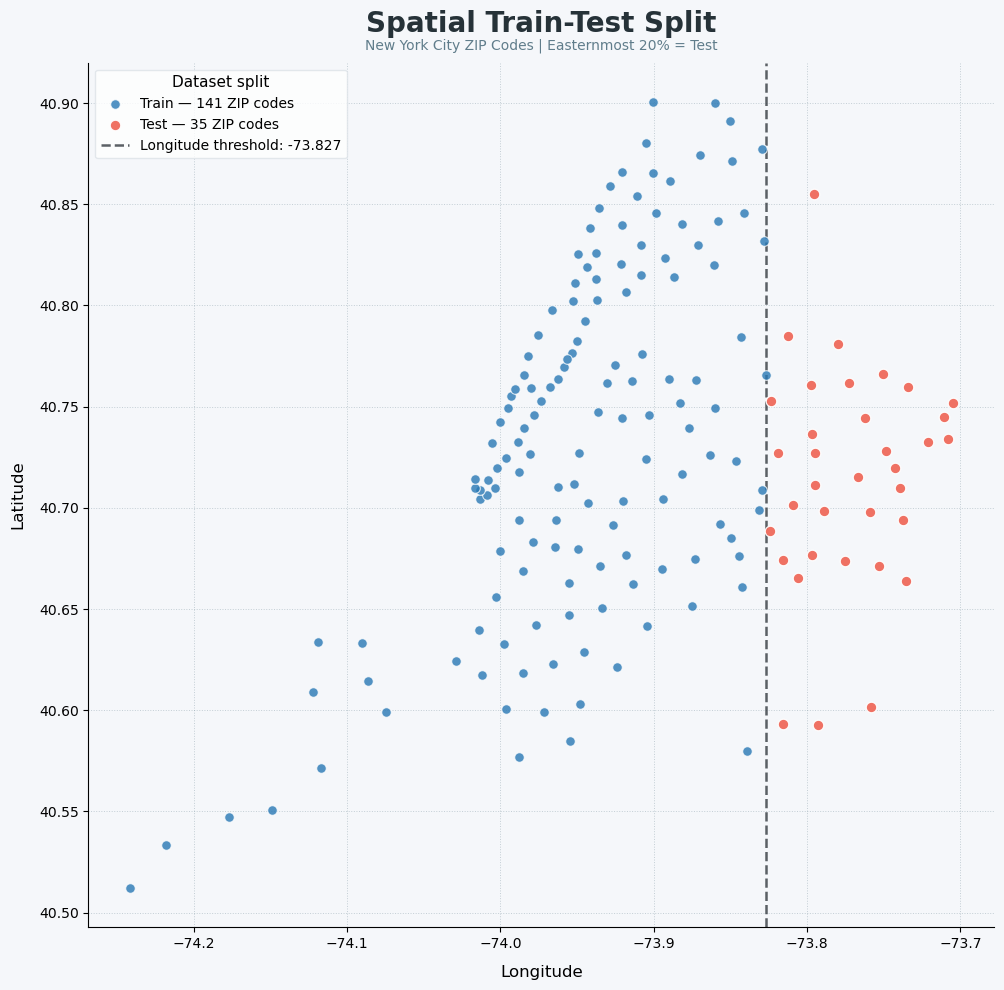

In [26]:

fig, ax = plt.subplots(figsize=(11, 10))

fig.patch.set_facecolor("#F5F7FA")
ax.set_facecolor("#F5F7FA")


gdf[gdf["set"] == "train"].plot(
    ax=ax,
    color="#2878B5",
    markersize=48,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.8,
    label=f"Train — {(gdf['set'] == 'train').sum()} ZIP codes",
    zorder=3
)


gdf[gdf["set"] == "test"].plot(
    ax=ax,
    color="#EF6A5B",
    markersize=58,
    alpha=0.95,
    edgecolor="white",
    linewidth=0.9,
    label=f"Test — {(gdf['set'] == 'test').sum()} ZIP codes",
    zorder=4
)


ax.axvline(
    hranica,
    color="#343A40",
    linestyle="--",
    linewidth=1.8,
    alpha=0.8,
    label=f"Longitude threshold: {hranica:.3f}"
)


ax.set_title(
    "Spatial Train-Test Split",
    fontsize=20,
    fontweight="bold",
    color="#263238",
    pad=22
)

ax.text(
    0.5, 1.015,
    "New York City ZIP Codes | Easternmost 20% = Test",
    transform=ax.transAxes,
    ha="center",
    fontsize=10,
    color="#607D8B"
)

ax.set_xlabel("Longitude", fontsize=12, labelpad=10)
ax.set_ylabel("Latitude", fontsize=12, labelpad=10)


legend = ax.legend(
    loc="upper left",
    frameon=True,
    fontsize=10,
    title="Dataset split",
    title_fontsize=11
)

legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("#DDE3E8")


ax.grid(
    True,
    linestyle=":",
    linewidth=0.7,
    alpha=0.4,
    color="#78909C"
)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "mapa_train_test.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()


In [27]:
gdf_m = gdf.to_crs("EPSG:32618")

train = gdf_m[gdf_m["set"] == "train"].copy()
test  = gdf_m[gdf_m["set"] == "test"].copy()

X_COLS = ["podiel_suv", "podiel_taxiky"]
Y_COL  = "podiel_np"

def make_knn(g, k=K):
    w = KNN.from_dataframe(g, k=k)
    w.transform = "R"
    return w

w_train = make_knn(train)      # iba tréningové dáta
w_full  = make_knn(gdf_m)      # celé územie
print("Train n =", w_train.n, "| Full n =", w_full.n, "| transform:", w_train.transform)

Train n = 141 | Full n = 176 | transform: R


In [28]:
y_tr = train[[Y_COL]].values
X_tr = train[X_COLS].values

ols = OLS(y_tr, X_tr, name_y=Y_COL, name_x=X_COLS)
sar = ML_Lag(y_tr, X_tr, w=w_train, name_y=Y_COL, name_x=X_COLS)

print(ols.summary)
print(sar.summary)

ML_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :        None
Dependent Variable  :   podiel_np                Number of Observations:         141
Mean dependent var  :      0.0623                Number of Variables   :           3
S.D. dependent var  :      0.0355                Degrees of Freedom    :         138
R-squared           :      0.2410
Adjusted R-squared  :      0.2300
Sum squared residual:    0.133842                F-statistic           :     21.9069
Sigma-square        :       0.001                Prob(F-statistic)     :   5.462e-09
S.E. of regression  :       0.031                Log likelihood        :     290.599
Sigma-square ML     :       0.001                Akaike info criterion :    -575.199
S.E of regression ML:      0.0308                Schwarz criterion     :    -566.352

----------

In [29]:
# Ak máte vlastné predict_ols() / predict_sar() zo cvičenia, tieto dve definície zmažte.
def predict_ols(model, X_new):
    """y_hat = b0 + X b"""
    b = model.betas.flatten()
    return b[0] + X_new @ b[1:]

def predict_sar(model, X_all, w_full, test_mask):
    """Reduced form SAR: y_hat = (I - rho W)^-1 (b0 + X b) na celom území, potom výber testu."""
    b = model.betas.flatten()
    beta, rho = b[:-1], b[-1]          # rho je v ML_Lag posledný koeficient
    xb = beta[0] + X_all @ beta[1:]
    W = w_full.full()[0]
    y_all = np.linalg.solve(np.eye(W.shape[0]) - rho * W, xb)
    return y_all[test_mask]

test_mask = (gdf_m["set"] == "test").values
X_all = gdf_m[X_COLS].values

pred_ols = predict_ols(ols, test[X_COLS].values)
pred_sar = predict_sar(sar, X_all, w_full, test_mask)

res = pd.DataFrame({
    "psc": test["psc"].values,
    "skutocne": test[Y_COL].values,
    "pred_OLS": pred_ols,
    "pred_SAR": pred_sar,
})
res["chyba_OLS"] = res["skutocne"] - res["pred_OLS"]
res["chyba_SAR"] = res["skutocne"] - res["pred_SAR"]
res.round(4)

,psc,skutocne,pred_OLS,pred_SAR,chyba_OLS,chyba_SAR
0,10464,0.0270,0.0341,0.0390,-0.0071,-0.0120
1,11001,0.1000,0.0736,0.0787,0.0264,0.0213
2,11004,0.0632,0.1017,0.1034,-0.0385,-0.0403
3,11040,0.1250,0.0703,0.0789,0.0547,0.0461
4,11355,0.2192,0.1187,0.1274,0.1005,0.0918
5,11357,0.2875,0.1063,0.1186,0.1812,0.1689
6,11358,0.3232,0.1177,0.1293,0.2055,0.1939
7,11360,0.1800,0.0916,0.1068,0.0884,0.0732
8,11361,0.1704,0.1099,0.1192,0.0604,0.0512
9,11362,0.0615,0.0881,0.0946,-0.0266,-0.0330


In [30]:
def metriky(y, yhat):
    e = y - yhat
    return {"RMSE": np.sqrt(np.mean(e**2)), "MAE": np.mean(np.abs(e))}

tab = pd.DataFrame({
    "OLS": metriky(res["skutocne"], res["pred_OLS"]),
    "SAR": metriky(res["skutocne"], res["pred_SAR"]),
}).T

print(tab.round(4))
print(f"\nrho (SAR) = {sar.rho:.4f}")
najlepsi = tab["RMSE"].idxmin()
print(f"Nižšiu predikčnú chybu (RMSE) dosiahol model: {najlepsi}")
res.to_csv("vysledky_test.csv", index=False)

       RMSE     MAE
OLS  0.0602  0.0390
SAR  0.0557  0.0358

rho (SAR) = 0.3141
Nižšiu predikčnú chybu (RMSE) dosiahol model: SAR


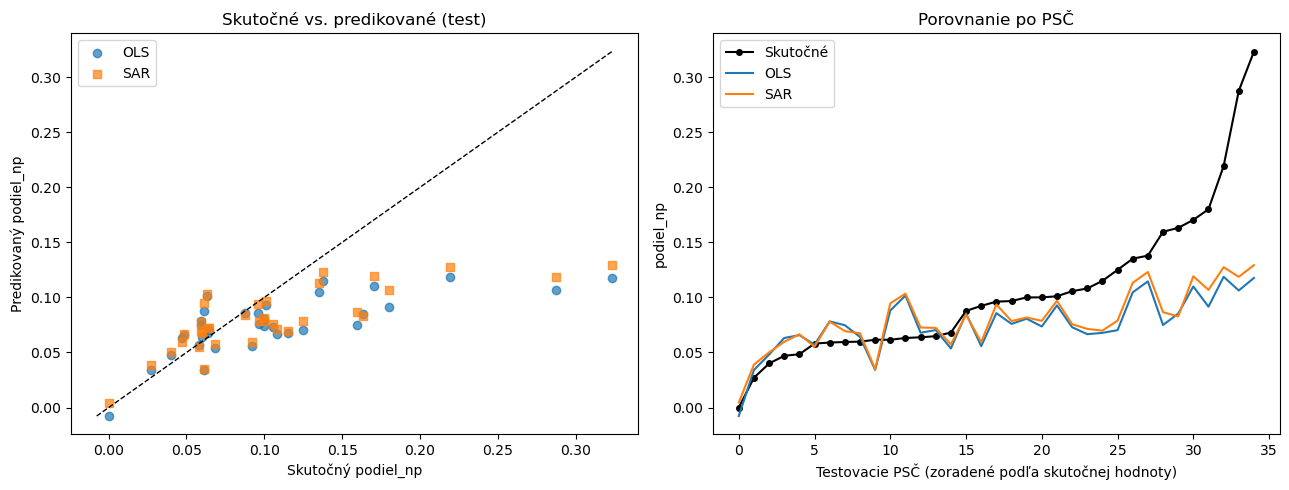

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
vals = res[["skutocne", "pred_OLS", "pred_SAR"]]
lim = [vals.min().min(), vals.max().max()]
ax.scatter(res["skutocne"], res["pred_OLS"], label="OLS", alpha=.7)
ax.scatter(res["skutocne"], res["pred_SAR"], label="SAR", alpha=.7, marker="s")
ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("Skutočný podiel_np"); ax.set_ylabel("Predikovaný podiel_np")
ax.set_title("Skutočné vs. predikované (test)")
ax.legend()

ax = axes[1]
r = res.sort_values("skutocne").reset_index(drop=True)
ax.plot(r["skutocne"], "k-o", label="Skutočné", ms=4)
ax.plot(r["pred_OLS"], "-", label="OLS")
ax.plot(r["pred_SAR"], "-", label="SAR")
ax.set_xlabel("Testovacie PSČ (zoradené podľa skutočnej hodnoty)"); ax.set_ylabel("podiel_np")
ax.set_title("Porovnanie po PSČ")
ax.legend()

plt.tight_layout()
plt.savefig("porovnanie_predikcii.png", dpi=150)
plt.show()